# Task 3: Stacked ensemble detector (WikiBio)

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

SEED = 42
T1_PATH = "results/task1_wikibio.csv"
T2_PATH = "results/task2_wikibio.csv"
RESULT_DIR = "results"

FEAT_T1 = ["mean_logprob", "mean_entropy"]
FEAT_T2 = ["bertscore_inconsistency", "nli_contradiction"]
FEAT_ALL = FEAT_T1 + FEAT_T2

In [24]:
key = ["bio_id", "sentence_id"]
t1 = pd.read_csv(T1_PATH)[key + ["label", "split"] + FEAT_T1]
t2 = pd.read_csv(T2_PATH)[key + ["label", "split"] + FEAT_T2]

df = t1.merge(t2, on=key, suffixes=("", "_t2"), validate="one_to_one")

assert len(df) == len(t1) == len(t2)
assert (df["label"] == df["label_t2"]).all() and (df["split"] == df["split_t2"]).all()
assert df[FEAT_ALL].notna().all().all()

In [25]:
df = df.drop(columns=["label_t2", "split_t2"])

train = df[df["split"] == "train"].reset_index(drop=True)
test  = df[df["split"] == "test"].reset_index(drop=True)
assert set(train["bio_id"]).isdisjoint(set(test["bio_id"]))

In [26]:
print(f"Train: {len(train)} sentences / {train['bio_id'].nunique()} passages | positive rate {train['label'].mean():.3f}")
print(f"Test : {len(test)} sentences / {test['bio_id'].nunique()} passages | positive rate {test['label'].mean():.3f}")

Train: 1525 sentences / 190 passages | positive rate 0.721
Test : 383 sentences / 48 passages | positive rate 0.762


## Fit the meta-classifiers on the train split

In [27]:
y_train, y_test = train["label"].values, test["label"].values

inner_cv = list(GroupKFold(n_splits=5).split(train, y_train, groups=train["bio_id"]))

def fit_lr(cols):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10, 100], cv=inner_cv,
                             scoring="average_precision", max_iter=2000),
    )
    return model.fit(train[cols].values, y_train)

models = {
    "LR on Task 1 features (2)": (fit_lr(FEAT_T1),  FEAT_T1),
    "LR on Task 2 features (2)": (fit_lr(FEAT_T2),  FEAT_T2),
    "Task 3 ensemble (all 4)":   (fit_lr(FEAT_ALL), FEAT_ALL),
}

for name, (m, cols) in models.items():
    lr = m[-1]
    print(f"{name}: C={lr.C_[0]}")
    print("   ", dict(zip(cols, lr.coef_[0].round(3))))

LR on Task 1 features (2): C=0.01
    {'mean_logprob': np.float64(0.301), 'mean_entropy': np.float64(0.145)}
LR on Task 2 features (2): C=1.0
    {'bertscore_inconsistency': np.float64(0.613), 'nli_contradiction': np.float64(0.453)}
Task 3 ensemble (all 4): C=0.01
    {'mean_logprob': np.float64(0.245), 'mean_entropy': np.float64(0.128), 'bertscore_inconsistency': np.float64(0.404), 'nli_contradiction': np.float64(0.331)}


/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.w

## eval

In [28]:
preds = {
    "T1 raw: -mean log-prob":   -test["mean_logprob"].values,
    "T1 raw: mean entropy":      test["mean_entropy"].values,
    "T2 raw: BERTScore":         test["bertscore_inconsistency"].values,
    "T2 raw: NLI":               test["nli_contradiction"].values,
}

In [29]:
def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

for d_ in (train, test, df):
    d_["nli_logit"] = logit(d_["nli_contradiction"])

FEAT_ALL_L = ["mean_logprob", "mean_entropy", "bertscore_inconsistency", "nli_logit"]
m = fit_lr(FEAT_ALL_L)
p = m.predict_proba(test[FEAT_ALL_L].values)[:, 1]
print("Logit-NLI ensemble AUC-PR (test):", round(average_precision_score(y_test, p), 4))

preds["Task 3 ensemble (logit NLI)"] = p

Logit-NLI ensemble AUC-PR (test): 0.8566


/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.w

In [30]:
for name, (m, cols) in models.items():
    preds[name] = m.predict_proba(test[cols].values)[:, 1]

In [31]:
rows = [{"method": "Random baseline (positive rate)", "AUC-PR": y_test.mean(), "ROC-AUC": 0.5}]
for name, p in preds.items():
    rows.append({"method": name, "AUC-PR": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p)})

In [32]:
summary = pd.DataFrame(rows).set_index("method").round(4)

summary

,AUC-PR,ROC-AUC
method,,
Random baseline (positive rate),0.7624,0.5000
T1 raw: -mean log-prob,0.7101,0.4445
T1 raw: mean entropy,0.7189,0.4438
T2 raw: BERTScore,0.8148,0.6260
T2 raw: NLI,0.8550,0.6570
Task 3 ensemble (logit NLI),0.8566,0.6630
LR on Task 1 features (2),0.7754,0.5389
LR on Task 2 features (2),0.8489,0.6872
Task 3 ensemble (all 4),0.8514,0.6590


In [33]:
summary.to_csv(f"{RESULT_DIR}/task3_summary.csv")

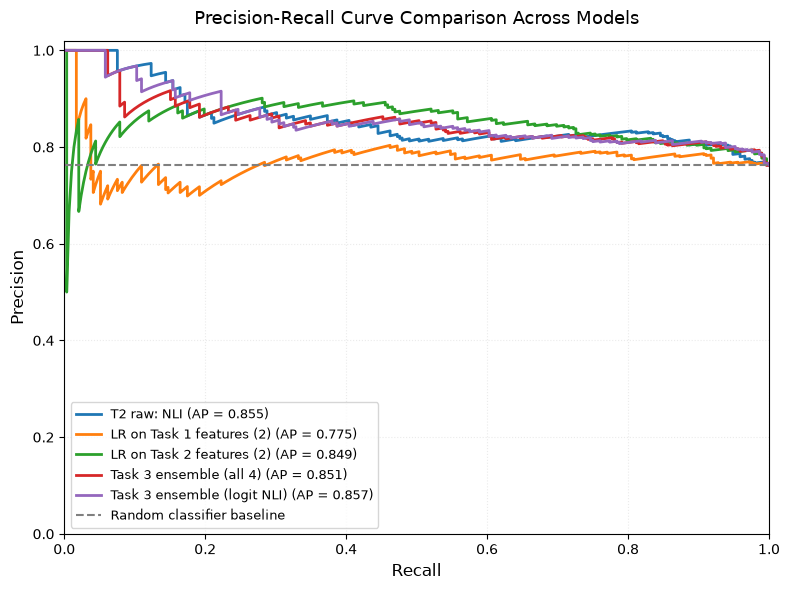

In [34]:
plt.figure(figsize=(8, 6))

model_names = [
    "T2 raw: NLI",
    "LR on Task 1 features (2)",
    "LR on Task 2 features (2)",
    "Task 3 ensemble (all 4)",
    "Task 3 ensemble (logit NLI)"
]

for name in model_names:
    precision, recall, _ = precision_recall_curve(y_test, preds[name])
    ap_score = average_precision_score(y_test, preds[name])
    plt.plot(recall, precision, linewidth=2, label=f"{name} (AP = {ap_score:.3f})")

plt.axhline(y=y_test.mean(), color="gray", linestyle="--", linewidth=1.5, label="Random classifier baseline")
plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.title("Precision-Recall Curve Comparison Across Models", fontsize=13, pad=12)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.25, linestyle=":")
plt.legend(loc="best", fontsize=9, frameon=True)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/task3_pr_wikibio.png", dpi=300, bbox_inches="tight")

plt.show()

## Uncertainty: bootstrap over test passages

In [35]:
rng = np.random.default_rng(SEED)
groups = test.groupby("bio_id").indices
passage_ids = list(groups)

B = 1000
names = ["T1 raw: mean entropy", "T2 raw: NLI",
         "LR on Task 1 features (2)", "LR on Task 2 features (2)",
         "Task 3 ensemble (all 4)", "Task 3 ensemble (logit NLI)"]
boot = {n: [] for n in names}
boot_diff = [] 
boot_diff_logit = [] 
boot_diff_nli = []                      

In [36]:
for _ in range(B):
    chosen = rng.choice(passage_ids, size=len(passage_ids), replace=True)
    idx = np.concatenate([groups[g] for g in chosen])
    yb = y_test[idx]
    if yb.min() == yb.max():
        continue
    aps = {n: average_precision_score(yb, preds[n][idx]) for n in names}
    for n in names:
        boot[n].append(aps[n])
    boot_diff.append(aps["Task 3 ensemble (all 4)"] - aps["LR on Task 2 features (2)"])
    boot_diff_logit.append(aps["Task 3 ensemble (logit NLI)"] - aps["Task 3 ensemble (all 4)"])
    boot_diff_nli.append(aps["Task 3 ensemble (logit NLI)"] - aps["T2 raw: NLI"])

In [37]:
ci = pd.DataFrame({n: {"AUC-PR (test)": average_precision_score(y_test, preds[n]),
                       "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5)}
                   for n, v in boot.items()}).T.round(4)

In [38]:
ci

,AUC-PR (test),95% CI low,95% CI high
T1 raw: mean entropy,0.7189,0.6361,0.8207
T2 raw: NLI,0.8550,0.7891,0.9124
LR on Task 1 features (2),0.7754,0.6980,0.8582
LR on Task 2 features (2),0.8489,0.7869,0.9066
Task 3 ensemble (all 4),0.8514,0.7880,0.9048
Task 3 ensemble (logit NLI),0.8566,0.7951,0.9084


In [39]:
print("Bootstrap Comparison of Model Performance")
print("=" * 75)

comparisons = [
    ("Logit Ensemble vs. Original Ensemble", boot_diff_logit),
    ("Logit Ensemble vs. Raw NLI", boot_diff_nli)
]

for comparison, results in comparisons:
    results = np.asarray(results)

    mean_diff = results.mean()
    ci_lower, ci_upper = np.percentile(results, [2.5, 97.5])
    improvement_rate = (results > 0).mean()

    print(f"\nComparison: {comparison}")
    print(f"  Mean performance difference : {mean_diff:+.4f}")
    print(f"  95% Confidence Interval     : [{ci_lower:+.4f}, {ci_upper:+.4f}]")
    print(f"  Resamples with improvement  : {improvement_rate:.2%}")

Bootstrap Comparison of Model Performance

Comparison: Logit Ensemble vs. Original Ensemble
  Mean performance difference : +0.0051
  95% Confidence Interval     : [-0.0022, +0.0133]
  Resamples with improvement  : 90.70%

Comparison: Logit Ensemble vs. Raw NLI
  Mean performance difference : +0.0008
  95% Confidence Interval     : [-0.0258, +0.0282]
  Resamples with improvement  : 51.70%


In [40]:
d = np.array(boot_diff)
print("Performance Comparison: Ensemble vs. Task-2 Logistic Regression")
print("-" * 65)

print(f"Mean performance difference       : {d.mean():+.4f}")
print(
    f"95% Confidence Interval           : "
    f"[{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]"
)
print(
    f"Proportion of resamples where the "
    f"ensemble performs better         : {(d > 0).mean():.2%}"
)

Performance Comparison: Ensemble vs. Task-2 Logistic Regression
-----------------------------------------------------------------
Mean performance difference       : +0.0013
95% Confidence Interval           : [-0.0179, +0.0197]
Proportion of resamples where the ensemble performs better         : 54.00%


### Robustness check: grouped 5-fold cross-validation on all passages

In [41]:
y_all = df["label"].values
outer_cv = GroupKFold(n_splits=5)
cv_rows = {"Random baseline": y_all.mean()}

In [42]:
for name, cols in [("LR on Task 1 features (2)", FEAT_T1),
                   ("LR on Task 2 features (2)", FEAT_T2),
                   ("Task 3 ensemble (all 4)", FEAT_ALL)]:
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    p = cross_val_predict(pipe, df[cols].values, y_all, groups=df["bio_id"], cv=outer_cv, method="predict_proba")[:, 1]
    cv_rows[name] = average_precision_score(y_all, p)

In [43]:
pd.Series(cv_rows, name="AUC-PR (grouped 5-fold CV, all data)").round(4).to_frame()

,"AUC-PR (grouped 5-fold CV, all data)"
Random baseline,0.7296
LR on Task 1 features (2),0.7489
LR on Task 2 features (2),0.8050
Task 3 ensemble (all 4),0.8111


In [44]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
p_cv = cross_val_predict(pipe, df[FEAT_ALL_L].values, df["label"].values,
                         groups=df["bio_id"], cv=GroupKFold(n_splits=5),
                         method="predict_proba")[:, 1]
print("Logit-NLI ensemble AUC-PR (grouped 5-fold CV):",
      round(average_precision_score(df["label"].values, p_cv), 4))

Logit-NLI ensemble AUC-PR (grouped 5-fold CV): 0.8223


In [45]:

N_SEEDS = 20
C_VALUE = 0.01 

results = []

X = df[FEAT_ALL_L].values
y = df["label"].values
groups = df["bio_id"].values

for seed in range(N_SEEDS):

    for split_type in ["biography", "sentence"]:

        if split_type == "biography":
            splitter = GroupShuffleSplit(
                n_splits=1, test_size=0.2, random_state=seed
            )
            train_idx, test_idx = next(
                splitter.split(X, y, groups)
            )

        else:
            train_idx, test_idx = train_test_split(
                np.arange(len(y)),
                test_size=0.2,
                random_state=seed,
                stratify=y
            )

        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=C_VALUE, max_iter=2000)
        )

        model.fit(X[train_idx], y[train_idx])

        predictions = model.predict_proba(X[test_idx])[:, 1]

        auc_pr = average_precision_score(
            y[test_idx], predictions
        )

        results.append({
            "seed": seed,
            "split": split_type,
            "auc_pr": auc_pr
        })

results_df = pd.DataFrame(results)

summary = results_df.groupby("split")["auc_pr"].agg(
    ["mean", "std"]
).round(4)

print("20-seed comparison:")
display(summary)


20-seed comparison:


,mean,std
split,,
biography,0.8365,0.0387
sentence,0.8319,0.0182
